# Average Prediction Test

This notebook tests average predictions and compares them with real values.

In [1]:
from anomalouslib.models.model_handler import load_model
from anomalouslib.models.testing_utils import predict_continuous
from anomalouslib.data.DatasetGenerator import DatasetGenerator
from anomalouslib.data.preprocessing import generate_regressor_tensors

!!!!!!!!!!!!!!!!!!!!!! UPDATE FUNCTION (load_model) IN THE LIBRARY!!!!!!!!!!!!!!!!!!!!

In [3]:
import torch
import dill
import os
import inspect
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load("FractionalBrownianMotionHurstRegressor.pth", map_location=device, pickle_module=dill)
print(checkpoint.keys())

dict_keys(['model_name', 'model_type', 'model_source', 'state_dict', 'params', 'input_channels'])


In [26]:
import torch
import dill
import os
import inspect
import torch.nn as nn
import torch.nn.functional as F

def load_model(model_path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(model_path, map_location=device, pickle_module=dill)
    
    # Ejecutar el código fuente para recrear la clase
    exec(checkpoint["model_source"], globals())  # La clase se define en el scope global
    
    # Instanciar el modelo con sus argumentos originales
    model_class = globals()[checkpoint["model_source"].split("class ")[1].split("(")[0].strip()]
    model = model_class(**checkpoint["attributes"])
    model.load_state_dict(checkpoint["state_dict"])
    model.to(device)
    model.eval()
    if "le" in checkpoint and checkpoint["le"] is not None:
        return model, checkpoint["le"]
    return model

In [4]:
def value_difference(hurst):
    test_load_model = load_model("FractionalBrownianMotionHurstRegressor.pth")

    dg = DatasetGenerator(100)
    dataset = dg.generate_FractionalBrownianMotion(num_passos=200, hurst=hurst)
    x, y = generate_regressor_tensors(dataset, "Fractional Brownian Motion", "hurst")
    results = predict_continuous(test_load_model, x, y, num_samples=10, to_print=False)
    return results["Prediction"].mean().item(), results["Real Value"][0].item()

In [5]:
print(value_difference(hurst=0.1))
print(value_difference(hurst=0.3))
print(value_difference(hurst=0.5))
print(value_difference(hurst=0.7))
print(value_difference(hurst=0.9))

(0.03633593022823334, 0.0)
(0.2753855884075165, 0.25)
(0.5894585847854614, 0.5)
(0.8772990107536316, 0.75)


c:\Users\jmass\Documents\GitHub\TFG GEINF\AnomalousApp\venv\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


(0.9331838488578796, 1.0)


c:\Users\jmass\Documents\GitHub\TFG GEINF\AnomalousApp\venv\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


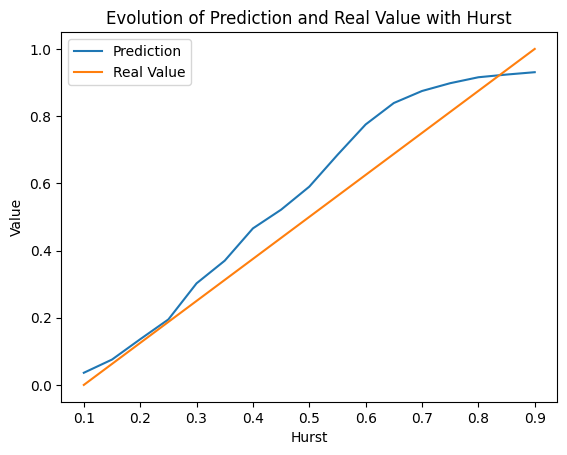

In [6]:
import numpy as np

import matplotlib.pyplot as plt

hurst_values = np.arange(0.1, 0.91, 0.05)
predicted = []
real = []

for h in hurst_values:
    pred, real_val = value_difference(h)
    predicted.append(pred)
    real.append(real_val)

plt.plot(hurst_values, predicted, label='Prediction')
plt.plot(hurst_values, real, label='Real Value')
plt.xlabel('Hurst')
plt.ylabel('Value')
plt.title('Evolution of Prediction and Real Value with Hurst')
plt.legend()
plt.show()